# Studi Kasus 3: Career and Competition in Industrial Era with GIS (Smart City & AI Spatial Logistics)

**Topik Webinar:** *Career and Competition in Industrial Era with GIS*  
**Fokus Implementasi:** Peran strategis lulusan IT sebagai **Pengembang Sistem Geospasial (*GIS Developer*)**—bukan sekadar pengguna akhir GUI—dengan mengintegrasikan pemrograman spasial Python, algoritma AI (*Weighted Spatial Clustering*), dan optimasi rute jaringan logistik (*Capacitated Vehicle Routing / 2-Opt TSP Heuristic*) yang kompatibel dengan ekosistem open-source **[QGIS](https://www.qgis.org/)** dan **[OpenStreetMap](https://www.openstreetmap.org/)**.

### Skenario Industri: Manajemen Aset Smart City & Jaringan Logistik Kota Bengkulu
Menggunakan data geospasial 500 titik aset dan simpul distribusi di **9 Kecamatan [Kota Bengkulu](https://siikolu.bengkulukota.go.id/profil_daerah/kondisi-geografis.html)** (`dataset 03 gis smartcity logistik bengkulu.csv`), sistem yang kita kembangkan menyelesaikan 3 persoalan industri:
1. **Geodesic Spatial Indexing & Vulnerability Buffering:** Menghitung matriks jarak permukaan bumi (*Haversine Geodesic Distance*) dalam kilometer dan memetakan aset *Smart City* yang berada di zona rawan gangguan banjir.
2. **AI-Driven Micro-Fulfillment Hub Clustering:** Menentukan lokasi optimal 4 *Hub Gudang Distribusi* menggunakan algoritma **Demand-Weighted K-Means++** yang meminimalkan biaya logistik (*Ton-Kilometer*) sekaligus menghindari zona berisiko banjir tinggi.
3. **Optimasi Rute Distribusi Logistik (2-Opt Heuristic TSP):** Mengoptimalkan urutan pengiriman antar-simpul logistik sehingga memangkas total jarak tempuh armada secara signifikan dibanding rute sekuensial manual.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.dpi'] = 120
sns.set_theme(style="whitegrid")

DATASET_FILENAME = "dataset 03 gis smartcity logistik bengkulu.csv"
CANDIDATE_PATHS = [
    DATASET_FILENAME,
    f"/content/{DATASET_FILENAME}",
    f"/content/drive/MyDrive/Tugas Machine Learning Webinar/{DATASET_FILENAME}"
]

def load_or_generate_gis_data():
    for path in CANDIDATE_PATHS:
        if os.path.exists(path):
            print(f"[INFO] Memuat dataset geospasial Smart City & Logistik dari: {path}")
            return pd.read_csv(path)
    print("[INFO] Membangun ulang dataset deterministik geospasial Kota Bengkulu...")
    np.random.seed(303)
    n = 500
    kec_centers = [
        ("Teluk Segara", -3.789, 102.251, "Kawasan_Pesisir_Niaga"),
        ("Ratu Samban", -3.797, 102.261, "Pusat_Komersial_Kota"),
        ("Ratu Agung", -3.805, 102.273, "Permukiman_Padat"),
        ("Gading Cempaka", -3.826, 102.289, "Pusat_Pemerintahan_Pendidikan"),
        ("Singaran Pati", -3.813, 102.296, "Koridor_Perdagangan_Timur"),
        ("Muara Bangkahulu", -3.763, 102.276, "Koridor_Utara_Kampus_UNIB"),
        ("Sungai Serut", -3.777, 102.289, "Zona_Transisi_DAS"),
        ("Selebar", -3.852, 102.324, "Zona_Ekspansi_Logistik_Selatan"),
        ("Kampung Melayu", -3.872, 102.312, "Kawasan_Pelabuhan_PulauBaai_Industri")
    ]
    idx = np.random.choice(len(kec_centers), size=n, p=[0.09, 0.12, 0.14, 0.14, 0.11, 0.12, 0.07, 0.11, 0.10])
    kec_name = [kec_centers[i][0] for i in idx]
    zona_type = [kec_centers[i][3] for i in idx]
    lat = np.array([kec_centers[i][1] for i in idx]) + np.random.normal(0, 0.0075, size=n)
    lon = np.array([kec_centers[i][2] for i in idx]) + np.random.normal(0, 0.0075, size=n)
    asset_category = np.random.choice(
        ["Retail_Distribution_Node", "Smart_StreetLight_IoT", "ColdStorage_Pangan", "Posko_Logistik_Bencana", "Tower_Telekomunikasi"],
        size=n, p=[0.42, 0.24, 0.12, 0.12, 0.10]
    )
    daily_demand_ton = np.random.gamma(shape=2.4, scale=3.2, size=n).round(2)
    road_congestion_idx = np.clip(np.random.beta(a=2.5, b=3.0, size=n) * 10.0, 1.0, 10.0).round(2)
    flood_risk_score = np.where(np.isin(kec_name, ["Muara Bangkahulu", "Sungai Serut", "Kampung Melayu"]),
                                np.clip(np.random.normal(68, 14, size=n), 20, 98),
                                np.clip(np.random.normal(28, 12, size=n), 5, 75)).round(1)
    iot_uptime_pct = np.clip(99.5 - 0.12 * flood_risk_score + np.random.normal(0, 1.8, size=n), 75.0, 100.0).round(2)
    df_out = pd.DataFrame({
        "asset_id": [f"GIS-BKL-{3000+i}" for i in range(n)], "kecamatan": kec_name,
        "zona_tata_ruang": zona_type, "asset_category": asset_category,
        "latitude": lat.round(5), "longitude": lon.round(5), "daily_demand_ton": daily_demand_ton,
        "road_congestion_idx": road_congestion_idx, "flood_risk_score": flood_risk_score,
        "iot_uptime_pct": iot_uptime_pct
    })
    df_out.to_csv(DATASET_FILENAME, index=False)
    return df_out

df_gis = load_or_generate_gis_data()
print(f"Total Aset & Simpul Spasial Terdaftar: {len(df_gis)} titik di {df_gis['kecamatan'].nunique()} Kecamatan")
print(df_gis.groupby(["kecamatan", "zona_tata_ruang"]).agg(
    Jumlah_Titik=("asset_id", "count"),
    Total_Demand_Ton=("daily_demand_ton", "sum"),
    Skor_Risiko_Banjir=("flood_risk_score", "mean"),
    IoT_Uptime_Pct=("iot_uptime_pct", "mean")
).round(2).to_string())

[INFO] Memuat dataset geospasial Smart City & Logistik dari: dataset 03 gis smartcity logistik bengkulu.csv
Total Aset & Simpul Spasial Terdaftar: 500 titik di 9 Kecamatan
                                                       Jumlah_Titik  Total_Demand_Ton  Skor_Risiko_Banjir  IoT_Uptime_Pct
kecamatan        zona_tata_ruang                                                                                         
Gading Cempaka   Pusat_Pemerintahan_Pendidikan                   57            398.16               27.93           96.23
Kampung Melayu   Kawasan_Pelabuhan_PulauBaai_Industri            55            431.83               68.76           91.34
Muara Bangkahulu Koridor_Utara_Kampus_UNIB                       53            371.97               69.37           91.04
Ratu Agung       Permukiman_Padat                                75            527.79               29.46           96.14
Ratu Samban      Pusat_Komersial_Kota                            60            451.17           

### Tahap 1: Geodesic Distance Engine & AI Demand-Weighted Spatial Clustering
Seorang *GIS Developer* membangun fungsi perhitungan jarak geodesik **Haversine** untuk menghindari distorsi proyeksi derajat ke kilometer di wilayah ekuator Sumatera, lalu menerapkan algoritma **Demand-Weighted K-Means++** yang memperhitungkan volume permintaan harian (`daily_demand_ton`) dan penalti kerentanan banjir untuk menentukan titik koordinat optimal **4 Smart Logistics Micro-Hubs**.

In [3]:
def haversine_matrix_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    phi1 = np.radians(lat1)[:, None]
    phi2 = np.radians(lat2)[None, :]
    dphi = np.radians(lat2[None, :] - lat1[:, None])
    dlambda = np.radians(lon2[None, :] - lon1[:, None])
    a = np.sin(dphi / 2.0)**2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlambda / 2.0)**2
    return 2.0 * R * np.arcsin(np.sqrt(np.clip(a, 0.0, 1.0)))

def fit_weighted_spatial_hubs(df, n_hubs=4, max_iter=60, seed=42):
    rng = np.random.default_rng(seed)
    coords = df[["latitude", "longitude"]].values
    safety_factor = np.clip(1.2 - df["flood_risk_score"].values / 100.0, 0.25, 1.0)
    weights = df["daily_demand_ton"].values * safety_factor
    
    centers = np.zeros((n_hubs, 2))
    first_idx = rng.choice(len(coords), p=weights / weights.sum())
    centers[0] = coords[first_idx]
    for k in range(1, n_hubs):
        dist_sq = np.min(haversine_matrix_km(coords[:, 0], coords[:, 1], centers[:k, 0], centers[:k, 1])**2, axis=1)
        probs = (dist_sq * weights) / np.sum(dist_sq * weights)
        centers[k] = coords[rng.choice(len(coords), p=probs)]
        
    for _ in range(max_iter):
        dmat = haversine_matrix_km(coords[:, 0], coords[:, 1], centers[:, 0], centers[:, 1])
        labels = np.argmin(dmat, axis=1)
        new_centers = np.zeros_like(centers)
        for k in range(n_hubs):
            mask = (labels == k)
            if np.any(mask):
                w_k = weights[mask][:, None]
                new_centers[k] = np.sum(coords[mask] * w_k, axis=0) / np.sum(w_k)
            else:
                new_centers[k] = centers[k]
        if np.max(np.abs(new_centers - centers)) < 1e-6:
            break
        centers = new_centers
        
    dmat_final = haversine_matrix_km(coords[:, 0], coords[:, 1], centers[:, 0], centers[:, 1])
    labels = np.argmin(dmat_final, axis=1)
    min_dist_km = np.min(dmat_final, axis=1)
    return centers, labels, min_dist_km

hub_centers, hub_labels, dist_to_hub_km = fit_weighted_spatial_hubs(df_gis, n_hubs=4)
df_gis["assigned_hub"] = [f"HUB-{k+1}" for k in hub_labels]
df_gis["dist_to_hub_km"] = dist_to_hub_km.round(3)
df_gis["ton_km_cost"] = (df_gis["daily_demand_ton"] * df_gis["dist_to_hub_km"]).round(3)

hub_summary = df_gis.groupby("assigned_hub").agg(
    Jumlah_Simpul_Dilayani=("asset_id", "count"),
    Total_Kapasitas_Harian_Ton=("daily_demand_ton", "sum"),
    Jarak_Layanan_Rata2_km=("dist_to_hub_km", "mean"),
    Total_Beban_TonKm=("ton_km_cost", "sum")
).round(2)
hub_summary["Koordinat_Hub_Lat"] = hub_centers[:, 0].round(5)
hub_summary["Koordinat_Hub_Lon"] = hub_centers[:, 1].round(5)

print("=== REKOMENDASI LOKASI OPTIMAL 4 SMART LOGISTICS MICRO-HUBS KOTA BENGKULU ===")
print(hub_summary.to_string())

=== REKOMENDASI LOKASI OPTIMAL 4 SMART LOGISTICS MICRO-HUBS KOTA BENGKULU ===
              Jumlah_Simpul_Dilayani  Total_Kapasitas_Harian_Ton  Jarak_Layanan_Rata2_km  Total_Beban_TonKm  Koordinat_Hub_Lat  Koordinat_Hub_Lon
assigned_hub                                                                                                                                     
HUB-1                             92                      621.54                    1.42             882.19           -3.76863          102.28188
HUB-2                            162                     1186.99                    1.37            1637.36           -3.79507          102.26093
HUB-3                            102                      730.06                    1.60            1171.43           -3.86097          102.31789
HUB-4                            144                     1062.86                    1.38            1429.74           -3.81642          102.29097


### Tahap 2: Optimasi Jaringan Rute Distribusi Logistik (Algoritma 2-Opt TSP Heuristic)
Setelah simpul dikelompokkan ke masing-masing *Micro-Hub*, kita mengoptimalkan urutan rute pengiriman armada pada 35 simpul prioritas utama (`Retail_Distribution_Node` & `Posko_Logistik_Bencana` dengan *demand* tertinggi) menggunakan algoritma **Nearest-Neighbor + 2-Opt Local Search** untuk menghilangkan persilangan jalur (*route crossing*) dan menekan konsumsi bahan bakar.

=== HASIL OPTIMASI RUTE DISTRIBUSI 35 SIMPUL LOGISTIK PRIORITAS ===
Total Jarak Tempuh Rute Sekuensial Manual (Baseline) : 196.92 km
Total Jarak Tempuh Rute Teroptimasi AI-GIS (2-Opt)   : 53.16 km
Penghematan Jarak & Konsumsi BBM Armada Harian       : 143.76 km (73.0% lebih efisien)


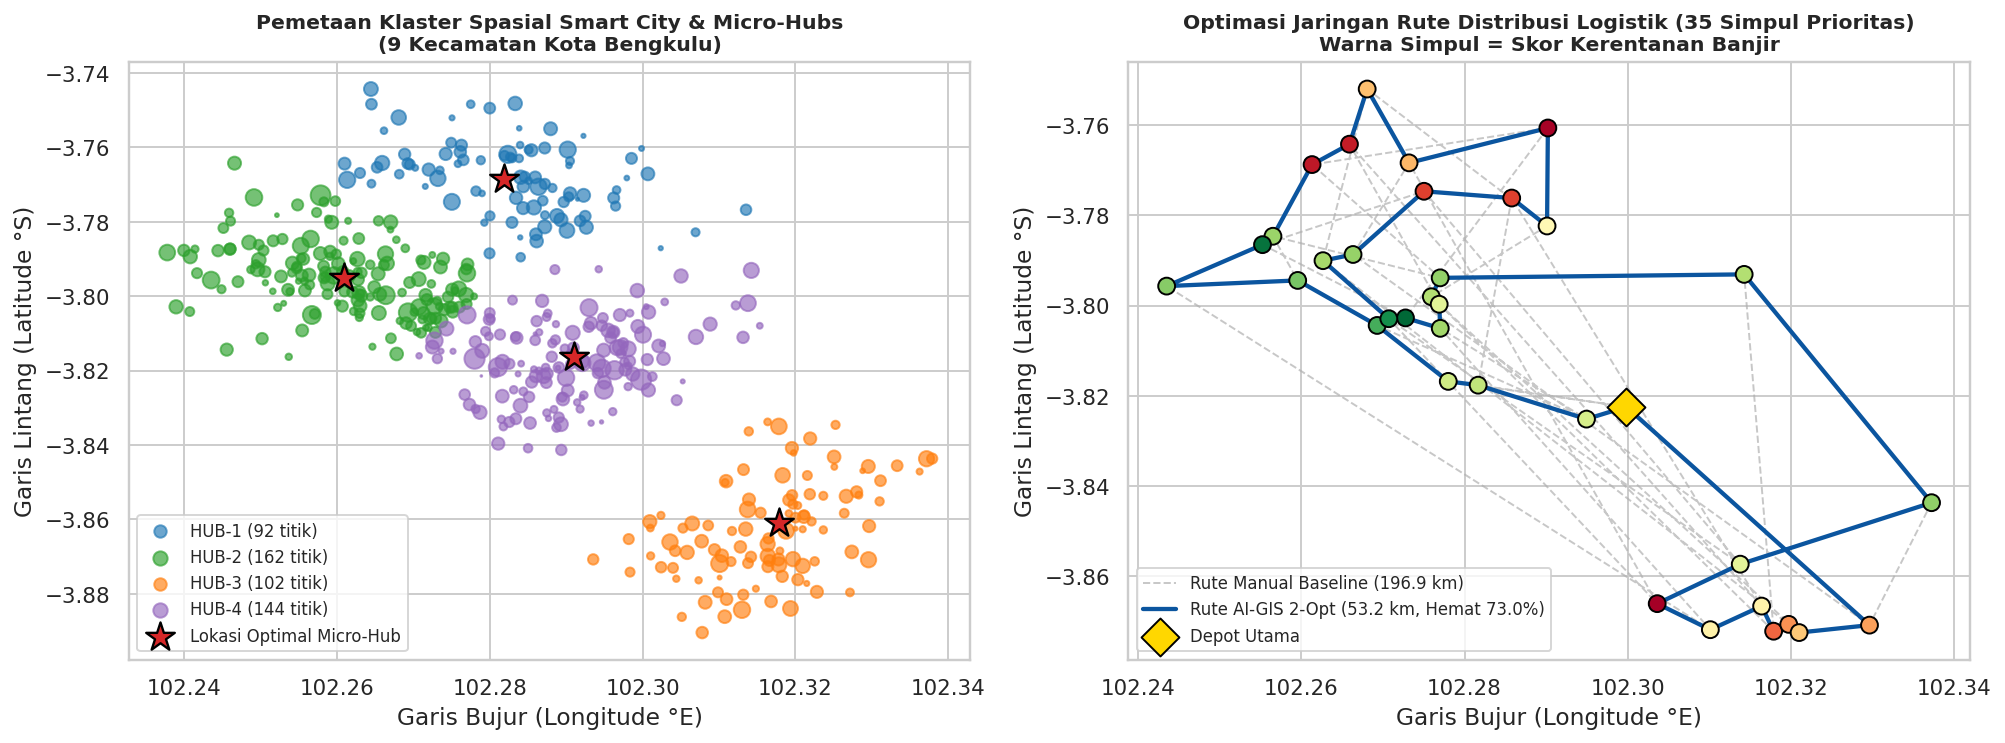

In [5]:
priority_nodes = df_gis[df_gis["asset_category"].isin(["Retail_Distribution_Node", "Posko_Logistik_Bencana"])].nlargest(35, "daily_demand_ton").reset_index(drop=True)
coords_p = priority_nodes[["latitude", "longitude"]].values
dist_mat = haversine_matrix_km(coords_p[:, 0], coords_p[:, 1], coords_p[:, 0], coords_p[:, 1])

def route_length_km(order, dmat):
    return float(sum(dmat[order[i], order[(i + 1) % len(order)]] for i in range(len(order))))

baseline_order = list(range(len(coords_p)))
baseline_km = route_length_km(baseline_order, dist_mat)

def solve_tsp_2opt(dmat):
    n = len(dmat)
    unvisited = set(range(1, n))
    tour = [0]
    while unvisited:
        last = tour[-1]
        nxt = min(unvisited, key=lambda j: dmat[last, j])
        tour.append(nxt)
        unvisited.remove(nxt)
        
    improved = True
    while improved:
        improved = False
        for i in range(1, n - 2):
            for j in range(i + 1, n):
                if j - i == 1:
                    continue
                new_tour = tour[:]
                new_tour[i:j] = tour[j - 1:i - 1:-1]
                if route_length_km(new_tour, dmat) < route_length_km(tour, dmat) - 1e-6:
                    tour = new_tour
                    improved = True
    return tour

opt_order = solve_tsp_2opt(dist_mat)
opt_km = route_length_km(opt_order, dist_mat)
saving_pct = (1.0 - opt_km / baseline_km) * 100.0

print("=== HASIL OPTIMASI RUTE DISTRIBUSI 35 SIMPUL LOGISTIK PRIORITAS ===")
print(f"Total Jarak Tempuh Rute Sekuensial Manual (Baseline) : {baseline_km:.2f} km")
print(f"Total Jarak Tempuh Rute Teroptimasi AI-GIS (2-Opt)   : {opt_km:.2f} km")
print(f"Penghematan Jarak & Konsumsi BBM Armada Harian       : {baseline_km - opt_km:.2f} km ({saving_pct:.1f}% lebih efisien)")

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.5))

palette_hubs = {"HUB-1": "#1f77b4", "HUB-2": "#2ca02c", "HUB-3": "#ff7f0e", "HUB-4": "#9467bd"}
for hub_id, grp in df_gis.groupby("assigned_hub"):
    axes[0].scatter(grp["longitude"], grp["latitude"], s=grp["daily_demand_ton"]*4.5,
                    alpha=0.65, color=palette_hubs[hub_id], label=f"{hub_id} ({len(grp)} titik)")

axes[0].scatter(hub_centers[:, 1], hub_centers[:, 0], s=240, c="#d62728", marker="*",
                edgecolors="black", linewidths=1.2, zorder=10, label="Lokasi Optimal Micro-Hub")
axes[0].set_title("Pemetaan Klaster Spasial Smart City & Micro-Hubs\n(9 Kecamatan Kota Bengkulu)", fontsize=10.5, fontweight="bold")
axes[0].set_xlabel("Garis Bujur (Longitude °E)")
axes[0].set_ylabel("Garis Lintang (Latitude °S)")
axes[0].legend(loc="lower left", fontsize=8.5)

base_loop = baseline_order + [baseline_order[0]]
opt_loop = opt_order + [opt_order[0]]
axes[1].plot(coords_p[base_loop, 1], coords_p[base_loop, 0], ls="--", lw=1.0, color="#b0b0b0", alpha=0.7,
             label=f"Rute Manual Baseline ({baseline_km:.1f} km)")
axes[1].plot(coords_p[opt_loop, 1], coords_p[opt_loop, 0], ls="-", lw=2.2, color="#0b559f",
             label=f"Rute AI-GIS 2-Opt ({opt_km:.1f} km, Hemat {saving_pct:.1f}%)")
axes[1].scatter(coords_p[:, 1], coords_p[:, 0], c=priority_nodes["flood_risk_score"], cmap="RdYlGn_r",
                s=75, edgecolors="black", zorder=5)
axes[1].scatter(coords_p[0, 1], coords_p[0, 0], s=190, c="gold", marker="D", edgecolors="black", zorder=8, label="Depot Utama")
axes[1].set_title("Optimasi Jaringan Rute Distribusi Logistik (35 Simpul Prioritas)\nWarna Simpul = Skor Kerentanan Banjir", fontsize=10.5, fontweight="bold")
axes[1].set_xlabel("Garis Bujur (Longitude °E)")
axes[1].set_ylabel("Garis Lintang (Latitude °S)")
axes[1].legend(loc="lower left", fontsize=8.5)

plt.tight_layout()
plt.show()